<img src="https://www.pucsp.br/sites/default/files/download/brasao-PUCSP-assinatura-principal-RGB.png" style="float:right;" width="150px">

# Ciências da Computação [》](https://www.pucsp.br/graduacao/ciencia-da-computacao)

## Inteligência Artificial

IA ML (Machine Learning, Aprendizagem de Máquina)

**Objetivo desta aula e LAB explorar os modelos de Stacking, Baggin e Boosting.**

Inteligência Artificial - ML com Scikit-learn

## LAB
- Ler material do Geeks for Geeks (links)
- Para entrega (LAB semanal)
- Em duplas (pairing)
- Implementar um modelo de Boosting
- Implementar um modelo de Bagging
- Ou implementar um modelo de Stacking (Implementar 2 modelos ou 3)
- Usar dados do vega dataset (cada grupo usa um conjunto de dados diferente)
- Implementar com Scikit-Learn
- Publicar projeto no GitHub .ipynb
- Postar link da ativdade do MS Teams
- Citar o nome dos alunos

# Análise de Produtividade de Cevada (*Barley*) com Modelos de *Ensemble* (Bagging e Boosting)

**Autores da Dupla:**
* Priscilla de Souza Jardim
* Sofia Miyuki Moriya de Farias

**Disciplina:** Inteligência Artificial / Ciências da Computação  
**Objetivo:** Explorar, pré-processar e aplicar algoritmos de aprendizado de máquina baseados em *Ensemble* para prever o rendimento da cevada com base em variáveis agronômicas e geográficas.

### 1. Importação das Bibliotecas e Configuração Inicial

Nesta primeira etapa, importamos todas as bibliotecas necessárias para a manipulação dos dados (`pandas`, `numpy`), visualização gráfica (`matplotlib`, `seaborn`) e para a construção dos modelos de aprendizado de máquina baseados em *Ensemble* (`scikit-learn`).

In [3]:
# Importação das bibliotecas essenciais para manipulação de dados,
# gráficos e algoritmos de Machine Learning (Ensemble)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import BaggingRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor

# Configuração estética para os gráficos do Seaborn
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

### 2. Carregamento e Inspeção Inicial dos Dados

Carregamos o dataset histórico `barley` e realizamos uma inspeção inicial para verificar a estrutura das colunas, os tipos de dados, a presença de valores nulos e as estatísticas descritivas básicas da variável alvo (`yield` / rendimento).

In [5]:
# Carregamento do dataset 'barley' diretamente da biblioteca de dados do Vega
url = "https://raw.githubusercontent.com/vega/vega-datasets/master/data/barley.json"
df = pd.read_json(url)

# Exibindo as primeiras linhas para entender a estrutura das colunas
print("--- Primeiras 5 linhas do Dataset ---")
display(df.head())

# Verificando tipos de dados e se existem valores nulos (missing values)
print("\n--- Informações Estruturais do Dataset ---")
print(df.info())

# Estatísticas descritivas básicas da variável alvo (yield / rendimento)
print("\n--- Estatísticas Descritivas do Rendimento (Yield) ---")
print(df['yield'].describe())

--- Primeiras 5 linhas do Dataset ---


,yield,variety,year,site
0,27.00000,Manchuria,1931,University Farm
1,48.86667,Manchuria,1931,Waseca
2,27.43334,Manchuria,1931,Morris
3,39.93333,Manchuria,1931,Crookston
4,32.96667,Manchuria,1931,Grand Rapids



--- Informações Estruturais do Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   yield    120 non-null    float64
 1   variety  120 non-null    object 
 2   year     120 non-null    int64  
 3   site     120 non-null    object 
dtypes: float64(1), int64(1), object(2)
memory usage: 3.9+ KB
None

--- Estatísticas Descritivas do Rendimento (Yield) ---
count    120.000000
mean      34.420555
std       10.334706
min       14.433330
25%       26.875000
50%       32.866670
75%       41.399997
max       65.766700
Name: yield, dtype: float64


### 3. Análise Exploratória de Dados (EDA)

Criamos visualizações gráficas para compreender o comportamento dos dados antes da modelagem:
* **Gráfico 1 (Boxplot):** Exibe a distribuição da produtividade por variedade genética de cevada.
* **Gráfico 2 (Barplot):** Compara o rendimento médio obtido em cada local de cultivo (*site*).

/tmp/ipykernel_1386/564270176.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='variety', y='yield', palette='Set2')


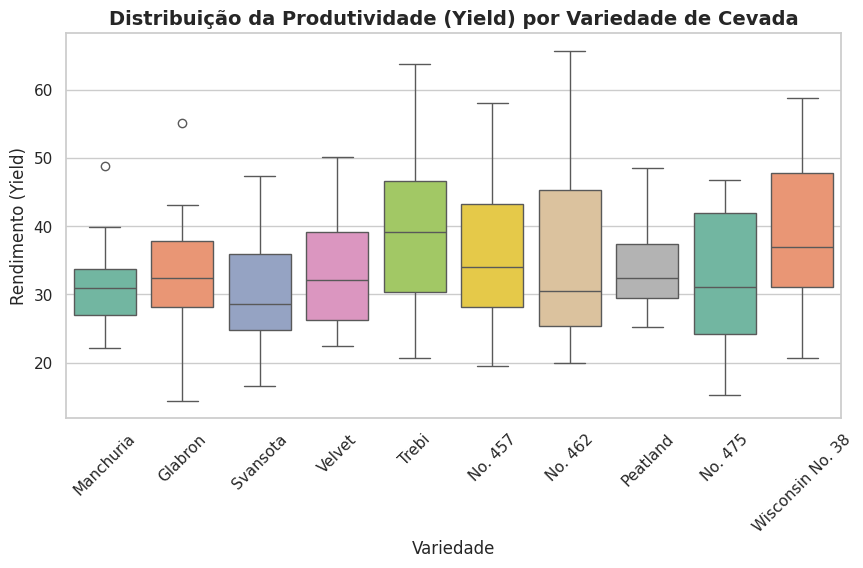

/tmp/ipykernel_1386/564270176.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=site_yield, x='site', y='yield', palette='viridis')


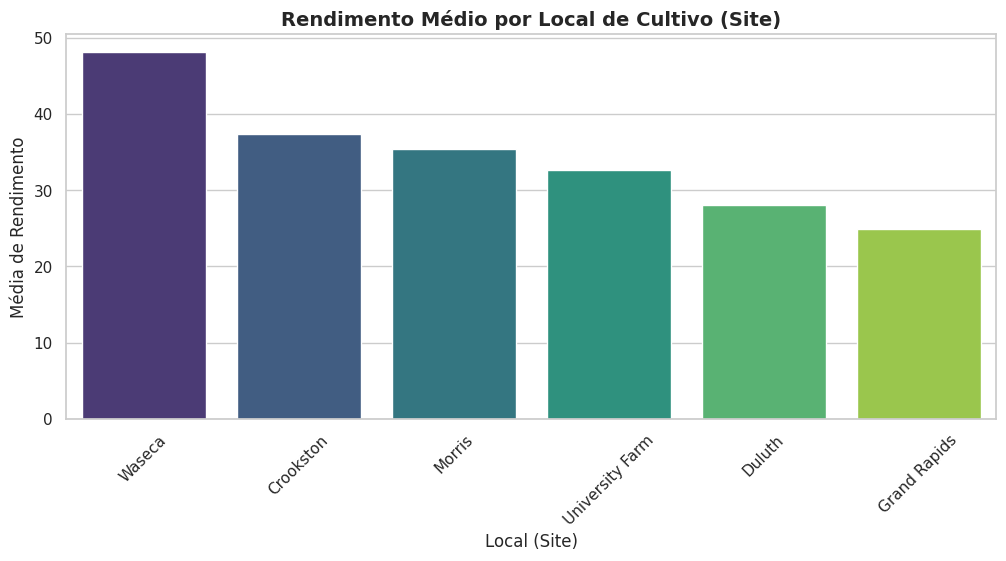

In [14]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='variety', y='yield', palette='Set2')
plt.title('Distribuição da Produtividade (Yield) por Variedade de Cevada', fontsize=14, fontweight='bold')
plt.xlabel('Variedade', fontsize=12)
plt.ylabel('Rendimento (Yield)', fontsize=12)
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(12, 5))
site_yield = df.groupby('site')['yield'].mean().reset_index().sort_values(by='yield', ascending=False)
sns.barplot(data=site_yield, x='site', y='yield', palette='viridis')
plt.title('Rendimento Médio por Local de Cultivo (Site)', fontsize=14, fontweight='bold')
plt.xlabel('Local (Site)', fontsize=12)
plt.ylabel('Média de Rendimento', fontsize=12)
plt.xticks(rotation=45)
plt.show()

### 4. Pré-processamento e Engenharia de Atributos

Como os algoritmos de Machine Learning exigem entradas numéricas, aplicamos a técnica de *One-Hot Encoding* nas colunas categóricas (`variety` e `site`). Em seguida, separamos as variáveis preditoras ($X$) da variável alvo ($y$) e dividimos o conjunto em **Treino (80%)** e **Teste (20%)**.

In [7]:
# Como os modelos de Machine Learning exigem entradas numéricas,
# aplicamos o One-Hot Encoding nas colunas categóricas ('variety' e 'site')
df_encoded = pd.get_dummies(df, columns=['variety', 'site'], drop_first=True)

# Separando a matriz de variáveis preditoras (X) e a variável alvo (y - yield)
X = df_encoded.drop(columns=['yield'])
y = df_encoded['yield']

# Dividindo o conjunto de dados em Treino (80%) e Teste (20%) para validação robusta
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Dimensões do conjunto de treino: {X_train.shape}")
print(f"Dimensões do conjunto de teste: {X_test.shape}")

Dimensões do conjunto de treino: (96, 15)
Dimensões do conjunto de teste: (24, 15)


### 5. Treinamento e Avaliação: Bagging Regressor

Inicializamos e treinamos o modelo de **Bagging** utilizando Árvores de Decisão como estimadores base. O Bagging reduz a variância do modelo ao treinar vários estimadores em subconjuntos amostrais paralelos, calculando em seguida as métricas de desempenho ($RMSE$ e $R^2$).

In [9]:
# Inicializando o Bagging Regressor utilizando Árvores de Decisão como estimadores base
bagging_model = BaggingRegressor(
    estimator=DecisionTreeRegressor(random_state=42),
    n_estimators=50,
    random_state=42
)

# Treinando o modelo com os dados de treino
bagging_model.fit(X_train, y_train)

# Realizando previsões no conjunto de teste
y_pred_bagging = bagging_model.predict(X_test)

# Calculando as métricas de avaliação de desempenho
rmse_bagging = np.sqrt(mean_squared_error(y_test, y_pred_bagging))
r2_bagging = r2_score(y_test, y_pred_bagging)

print("--- Desempenho do Bagging Regressor ---")
print(f"RMSE (Erro Quadrático Médio): {rmse_bagging:.4f}")
print(f"R² Score (Coeficiente de Determinação): {r2_bagging:.4f}")

--- Desempenho do Bagging Regressor ---
RMSE (Erro Quadrático Médio): 4.7647
R² Score (Coeficiente de Determinação): 0.7951


### 6. Treinamento e Avaliação: Gradient Boosting Regressor

Inicializamos e treinamos o modelo de **Boosting** (`GradientBoostingRegressor`). Ao contrário do Bagging, o Boosting constrói árvores de forma sequencial, onde cada nova árvore foca em corrigir os erros residuais (erros de previsão) deixados pela anterior.

In [8]:
# Inicializando o Gradient Boosting Regressor (construção sequencial de árvores para correção de resíduos)
boosting_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Treinando o modelo com os dados de treino
boosting_model.fit(X_train, y_train)

# Realizando previsões no conjunto de teste
y_pred_boosting = boosting_model.predict(X_test)

# Calculando as métricas de avaliação de desempenho
rmse_boosting = np.sqrt(mean_squared_error(y_test, y_pred_boosting))
r2_boosting = r2_score(y_test, y_pred_boosting)

print("--- Desempenho do Gradient Boosting Regressor ---")
print(f"RMSE (Erro Quadrático Médio): {rmse_boosting:.4f}")
print(f"R² Score (Coeficiente de Determinação): {r2_boosting:.4f}")

--- Desempenho do Gradient Boosting Regressor ---
RMSE (Erro Quadrático Médio): 5.0064
R² Score (Coeficiente de Determinação): 0.7738


### 7. Tabela Comparativa de Desempenho

Consolidamos as métricas de ambos os modelos em uma tabela comparativa direta para analisar qual estratégia de *Ensemble* obteve melhor acurácia na predição do rendimento da cevada.

In [11]:
# Organizando os resultados de ambos os modelos em um DataFrame estruturado
resultados_finais = pd.DataFrame({
    'Modelo de Ensemble': ['Bagging Regressor', 'Gradient Boosting Regressor'],
    'RMSE (Menor é Melhor)': [rmse_bagging, rmse_boosting],
    'R² Score (Maior é Melhor)': [r2_bagging, r2_boosting]
})

print("\nTabela Comparativa Final:")
display(resultados_finais)


Tabela Comparativa Final:


,Modelo de Ensemble,RMSE (Menor é Melhor),R² Score (Maior é Melhor)
0,Bagging Regressor,4.764658,0.795106
1,Gradient Boosting Regressor,5.006402,0.773788


### 8. Amostra Prática: Valores Reais vs. Previstos

Exibimos uma amostra prática comparando o valor real da colheita (`y_test`) lado a lado com as previsões numéricas geradas pelos modelos de Bagging e Boosting, facilitando a visualização concreta dos resultados.

In [12]:
# Criando um DataFrame para visualizar lado a lado o valor real e o que cada modelo previu
comparacao_previsoes = pd.DataFrame({
    'Rendimento Real (y_test)': y_test.values,
    'Previsto - Bagging': np.round(y_pred_bagging, 2),
    'Previsto - Boosting': np.round(y_pred_boosting, 2),
    'Erro Absoluto (Boosting)': np.round(np.abs(y_test.values - y_pred_boosting), 2)
})

print("--- Amostra das Primeiras 10 Previsões no Conjunto de Teste ---")
display(comparacao_previsoes.head(10))

--- Amostra das Primeiras 10 Previsões no Conjunto de Teste ---


,Rendimento Real (y_test),Previsto - Bagging,Previsto - Boosting,Erro Absoluto (Boosting)
0,29.86667,28.08,24.75,5.12
1,32.00000,29.99,26.67,5.33
2,32.96667,28.88,29.73,3.24
3,58.80000,54.75,56.59,2.21
4,43.76667,39.63,34.87,8.90
5,22.13333,20.93,21.42,0.71
6,38.50000,40.26,33.64,4.86
7,29.13333,28.88,29.32,0.18
8,24.93334,27.74,31.45,6.52
9,31.36667,25.02,21.61,9.75


### 9. Gráficos Finais: Desempenho Visual e Importância das Variáveis

Finalizamos a análise com dois gráficos essenciais:
* **Gráfico de Dispersão (Real vs. Previsto):** Mostra o quão próximas as previsões ficaram da linha de acerto ideal.
* **Importância das Variáveis (*Feature Importance*):** Revela quais fatores geográficos ou genéticos mais pesaram nas previsões do modelo.

/tmp/ipykernel_1386/3275415887.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importancias.values, y=importancias.index, ax=axes[1], palette='crest')


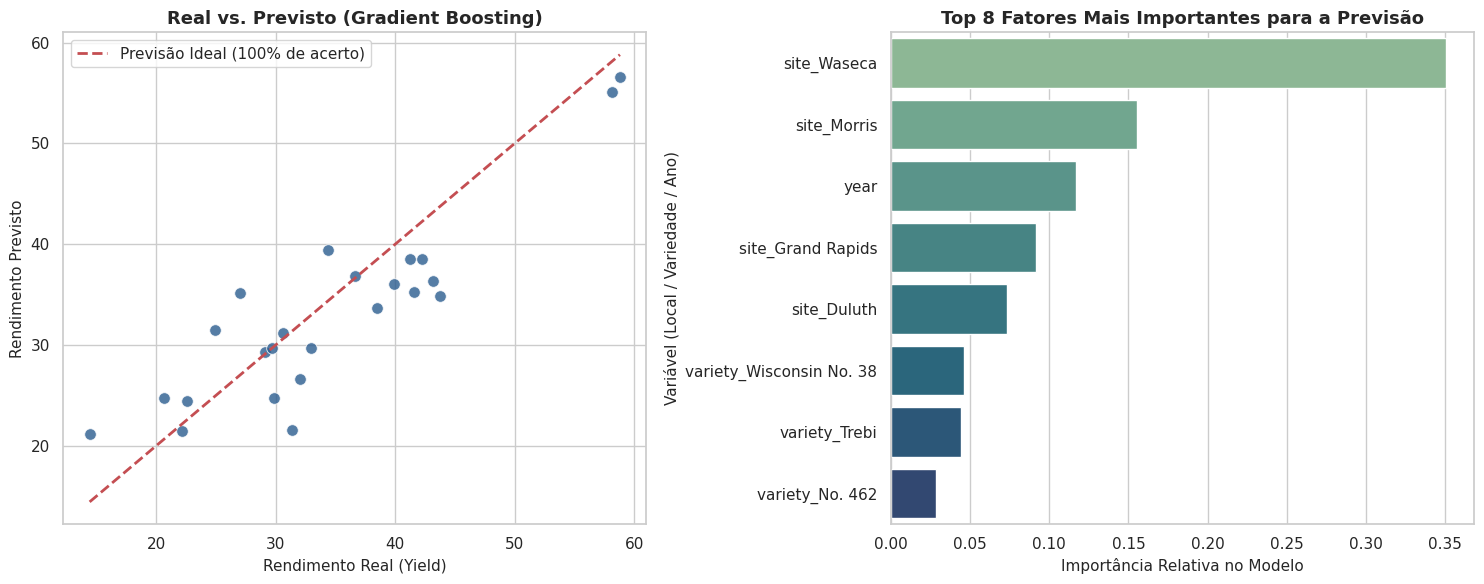

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Gráfico 1: Valores Reais vs. Valores Previstos (Gradient Boosting)
# Quanto mais próximos os pontos estiverem da linha tracejada vermelha, mais perfeita foi a previsão
sns.scatterplot(x=y_test, y=y_pred_boosting, ax=axes[0], color='#2b5c8f', alpha=0.8, s=70)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Previsão Ideal (100% de acerto)')
axes[0].set_title('Real vs. Previsto (Gradient Boosting)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Rendimento Real (Yield)', fontsize=11)
axes[0].set_ylabel('Rendimento Previsto', fontsize=11)
axes[0].legend()

# Gráfico 2: Importância das Variáveis (Feature Importance)
# Mostra quais fatores (locais, variedades ou ano) mais pesaram na decisão do modelo
importancias = pd.Series(boosting_model.feature_importances_, index=X.columns).sort_values(ascending=False).head(8)
sns.barplot(x=importancias.values, y=importancias.index, ax=axes[1], palette='crest')
axes[1].set_title('Top 8 Fatores Mais Importantes para a Previsão', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Importância Relativa no Modelo', fontsize=11)
axes[1].set_ylabel('Variável (Local / Variedade / Ano)', fontsize=11)

plt.tight_layout()
plt.show()